# Bisiklet Kiralama Talebi: Tek Bir Tabloyu Keşfetmek

Her hücre tek bir iş yapar. Yukarıdan aşağıya sırayla çalıştırın.

Bu defterde kullanılan tablo `day.csv`: Washington D.C.'deki Capital Bikeshare sisteminin 2011–2012 yıllarına ait günlük kiralama sayıları ile o günlerin hava durumu ve takvim bilgileri. Her satır bir gün. İş, bir model ya da panel kurulmadan önce tabloyu betimlemek.

Temel soru: **Hava durumu, mevsimsel ve zamansal faktörler bisiklet kiralama talebini nasıl etkiliyor?**

In [3]:
%matplotlib inline
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

## 1. Veriyi açma

`read_csv`, `day.csv` dosyasını bir tabloya yükler.

`shape` satır ve sütun sayısını verir.

`dtypes` her sütunun veri türünü gösterir.

`head()` ise veri setinin ilk beş satırını görmemizi sağlar.

Bu aşamada veriyi yalnızca inceliyoruz. Henüz hiçbir değeri değiştirmiyoruz.

In [4]:
df = pd.read_csv("data/day.csv")

print(df.shape)

print(df.dtypes)

df.head()

(731, 16)
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## 2. Yapıyı kontrol etme

Analizden önce tablonun neye izin verdiğine bakılır: hiçbir hücre boş mu, aynı satır iki kez yazılmış mı, hiçbir değer mümkün olan aralığın dışında mı?

`isna().sum()` her sütundaki boş hücre sayısını verir. `duplicated().sum()` tekrar eden satırları sayar. `temp`, `atemp`, `hum` ve `windspeed` 0 ile 1 arasına ölçeklendiği için bu aralığın dışında değer olmamalıdır.

Ayrıca bu veri setine özgü olarak toplam kiralama sayısının `casual + registered` toplamına eşit olup olmadığı, sıfır değerler ve kategorik değişkenlerde beklenmeyen kodlar kontrol edilir.

Bu aşamada yalnızca kontrol yapılır; hiçbir değer değiştirilmez veya silinmez.

In [5]:
print(df.isna().sum())
print("duplicate rows:", df.duplicated().sum())

weather = ["temp", "atemp", "hum", "windspeed"]

print("outside 0-1:")
print(((df[weather] < 0) | (df[weather] > 1)).sum())

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
duplicate rows: 0
outside 0-1:
temp         0
atemp        0
hum          0
windspeed    0
dtype: int64


In [6]:
print("cnt != casual + registered:",
      (df["cnt"] != df["casual"] + df["registered"]).sum())

print("zero values:")
print((df[weather + ["casual", "registered", "cnt"]] == 0).sum())

for col in ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]:
    print(col, sorted(df[col].unique().tolist()))

cnt != casual + registered: 0
zero values:
temp          0
atemp         0
hum           1
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
season [1, 2, 3, 4]
yr [0, 1]
mnth [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
holiday [0, 1]
weekday [0, 1, 2, 3, 4, 5, 6]
workingday [0, 1]
weathersit [1, 2, 3]


In [7]:
gap = (df["atemp"] - df["temp"]).abs()

df.assign(gap=gap).nlargest(
    5, "gap"
)[["dteday", "temp", "atemp", "gap"]]

,dteday,temp,atemp,gap
594,2012-08-17,0.723333,0.242400,0.480933
265,2011-09-23,0.609167,0.522125,0.087042
207,2011-07-27,0.775000,0.690667,0.084333
221,2011-08-10,0.766667,0.684983,0.081684
548,2012-07-02,0.781667,0.702038,0.079629


## 3. Gerekçeli değişiklikler

Yalnızca gerekçelendirebildiğimiz değişikliği yaparız. Bölüm 2'de iki şüpheli gözlem bulundu: nemi sıfır olan tek gün ve `temp` ile `atemp` arasındaki farkın alışılmadık büyük olduğu 2012-08-17. Şüpheli olmak hatalı olmakla aynı şey değildir. Bu yüzden önce her iki satırı, bir önceki ve bir sonraki günle birlikte yan yana koyarız: değer komşularına göre makul mü, yoksa tek başına mı duruyor?

Kanıtı gördükten sonra neyin değişeceğine karar verilir ve değişiklik nedeniyle birlikte bu bölümde yazılır. Hiçbir satır silinmez.

Aşağıdaki iki hücre yalnızca bakar, hiçbir şeyi değiştirmez.

In [8]:
context = ["dteday", "workingday", "weathersit", "temp", "atemp", "hum", "windspeed", "cnt"]
i = df.index[df["hum"] == 0][0]
df.loc[i - 1 : i + 1, context]

,dteday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
67,2011-03-09,1,2,0.295833,0.286608,0.775417,0.220150,1891
68,2011-03-10,1,3,0.389091,0.385668,0.000000,0.261877,623
69,2011-03-11,1,2,0.316522,0.305000,0.649565,0.232970,1977


In [9]:
j = df.index[df["dteday"] == "2012-08-17"][0]
df.loc[j - 1 : j + 1, context]

,dteday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
593,2012-08-16,1,1,0.719167,0.654688,0.519167,0.141796,7605
594,2012-08-17,1,1,0.723333,0.242400,0.570833,0.231354,7148
595,2012-08-18,0,1,0.678333,0.618071,0.603333,0.177867,7865


**Karar.** Bu bölümde bakılan iki şüpheli gözlemde yalnızca ilgili hücreler eksik (`pd.NA`) yapılır: 2011-03-10 tarihindeki `hum` ve 2012-08-17 tarihindeki `atemp`.

Neden satırın tamamı değil, yalnızca hücre? İki satırda da sorun tek bir değişkendedir. Aynı satırların diğer değerleri, özellikle `cnt`, komşu günlerle çelişmez. Satırı silmek bu geçerli görünen değerleri de atmak olurdu.

Neden değer olduğu gibi bırakılmıyor? Sıfır nem ve tutarsız hissedilen sıcaklık, dağılımı ve korelasyonları tek başına bozabilir. Eksik hücreler ortalama ya da medyanla doldurulmaz, çünkü uydurulmuş bir değer veride olmayan bir bilgiyi varmış gibi gösterir. pandas ortalama ve korelasyon gibi hesaplarda eksik hücreleri otomatik atlar: bu iki değişken 730 gözlemle hesaplanır.

Bu iki gözlem hata olarak kanıtlanmış değil, "şüpheli/tutarsız gözlem"dir ve nedenleri bilinmiyor. Değişiklik yalnızca bellekteki `df` üzerinde yapılır, `day.csv` dosyası olduğu gibi kalır. Hiçbir satır silinmez, `cnt` dahil diğer bütün sütunlar korunur.

In [10]:
hum_day = df["dteday"] == "2011-03-10"
atemp_day = df["dteday"] == "2012-08-17"
df.loc[hum_day, "hum"] = pd.NA
df.loc[atemp_day, "atemp"] = pd.NA

In [11]:
print(df.shape)
print(df[["hum", "atemp"]].isna().sum())
print("missing cells in total", int(df.isna().sum().sum()))

(731, 16)
hum      1
atemp    1
dtype: int64
missing cells in total 2


In [12]:
df.loc[hum_day | atemp_day, ["dteday", "temp", "atemp", "hum", "cnt"]]

,dteday,temp,atemp,hum,cnt
68,2011-03-10,0.389091,0.385668,NaN,623
594,2012-08-17,0.723333,NaN,0.570833,7148


## 4. Tek bir kategorinin sayıları: hava durumu (`weathersit`)

`weathersit` günün hava durumunu kodlar: 1 açık ya da az bulutlu, 2 sisli/puslu ve bulutlu, 3 hafif kar ya da hafif yağmur. Bölüm 2'de günlük veride yalnızca bu üç kodu gördük. Kodların doğal bir sırası vardır ama aralarındaki fark eşit olmak zorunda değildir: "ortalama hava durumu 1,6" bir anlam taşımaz. Bu yüzden her kodun frekansına bakarız, yani o koda sahip gün sayısına. En büyük frekans moddur. Bu sayılar gün sayısıdır, kiralama sayısı değil.

Oran, her frekansı bilinen etiketlerin toplamına böler (`p`), yüzde bunun 100 ile çarpılmış halidir. Farklı büyüklükteki grupları karşılaştırmayı kolaylaştırır. Bu sütunda eksik değer olmadığı için `dropna` hiçbir şeyi değiştirmez, ama hocanın kalıbını koruyoruz.

Bar grafiğinde her kategori için bir çubuk vardır, çubuğun uzunluğu frekansa eşittir ve eksen sıfırdan başlar. Hocanın örneğinde adlar sırasız olduğu için çubuklar büyüklüğe göre sıralanıyordu. Burada kodların doğal bir sırası olduğundan 1, 2, 3 sırasını koruyoruz. Kodlar henüz isimlere çevrilmedi, ham hâliyle gösteriliyor.

In [13]:
print(df["weathersit"].value_counts(dropna=False).sort_index())
known = df["weathersit"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

weathersit
1    463
2    247
3     21
Name: count, dtype: int64


,f,p,percent
weathersit,,,
1,463,0.633379,63.3
2,247,0.337893,33.8
3,21,0.028728,2.9


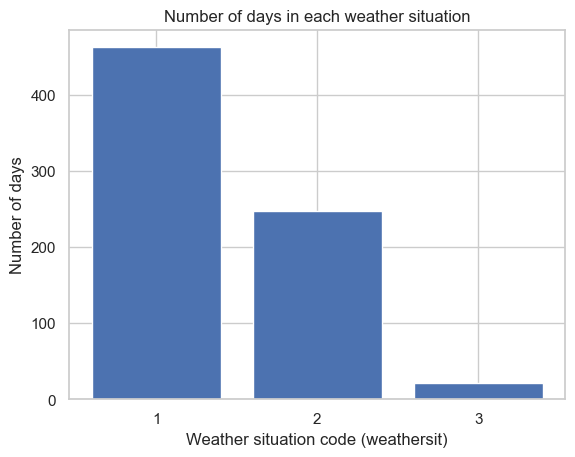

In [14]:
counts = df["weathersit"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Weather situation code (weathersit)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each weather situation")
plt.show()

## 4 (devam). Tek bir kategorinin sayıları: mevsim (`season`)

Aynı yöntemi bu kez `season` için uygularız: her kodun kaç günde göründüğü (frekans), oranı ve yüzdesi, ardından bar grafiği. Mevsim kodu 1'den 4'e sıralıdır ve döngüseldir (4'ten sonra yeniden 1 gelir); "ortalama mevsim kodu" bir anlam taşımaz. Frekans gün sayısıdır, kiralama sayısı değil.

**Etiket uyarısı.** Veri setinin iki kaynağı kodların anlamını farklı veriyor: UCI sayfasında 1 kış, 2 ilkbahar, 3 yaz, 4 sonbahar; `Readme.txt` dosyasında ise 1 ilkbahar, 2 yaz, 3 sonbahar, 4 kış yazıyor. İkisi birden doğru olamaz. Bu yüzden bu bölümde kodlara isim vermiyoruz, ham kodlarla (1, 2, 3, 4) çalışıyoruz. Doğru etiket, tarih sütunu (`dteday`) dönüştürüldükten sonra kodların hangi tarihlere denk geldiği kontrol edilerek ve kaynak belirtilerek seçilecek.

Çubuk grafiğinde kodların doğal sırası (1, 2, 3, 4) korunur. Hocanın örneğinde adlar sırasızdı ve çubuklar büyüklüğe göre sıralanıyordu; burada sıra bilgisi anlamlı olduğu için sıralamıyoruz.

In [15]:
print(df["season"].value_counts(dropna=False).sort_index())
known = df["season"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

season
1    181
2    184
3    188
4    178
Name: count, dtype: int64


,f,p,percent
season,,,
1,181,0.247606,24.8
2,184,0.251710,25.2
3,188,0.257182,25.7
4,178,0.243502,24.4


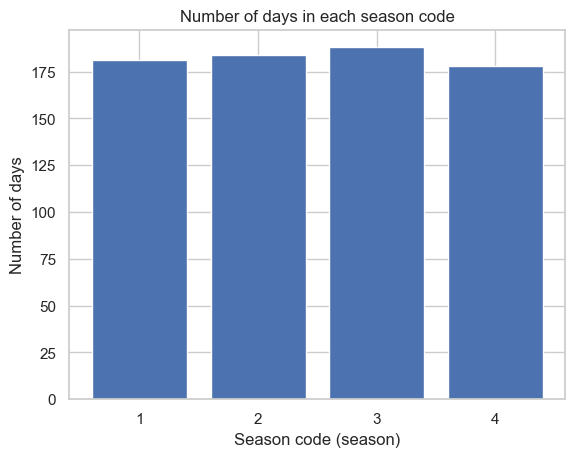

In [16]:
counts = df["season"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Season code (season)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each season code")
plt.show()

## 4 (devam). Tek bir kategorinin sayıları: çalışma günü (`workingday`)

`workingday` ikili bir koddur: veri dokümantasyonuna göre gün hafta sonu ya da resmi tatil değilse 1, aksi hâlde 0. Yani 0 grubu tek tür gün değil, hafta sonları ile tatillerin karışımıdır. İkili bir kodun ortalamasını yorumlamayız; bunun yerine her kodun frekansına (kaç gün) ve oranına bakarız. Frekans gün sayısıdır, kiralama sayısı değil.

Aynı kalıp uygulanır: frekans, oran (`p`), yüzde, ardından bar grafiği. Kodların doğal sırası 0, 1 olarak korunur. Kodlar ham hâliyle gösterilir, etiket eklenmez.

In [17]:
print(df["workingday"].value_counts(dropna=False).sort_index())
known = df["workingday"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

workingday
0    231
1    500
Name: count, dtype: int64


,f,p,percent
workingday,,,
0,231,0.316005,31.6
1,500,0.683995,68.4


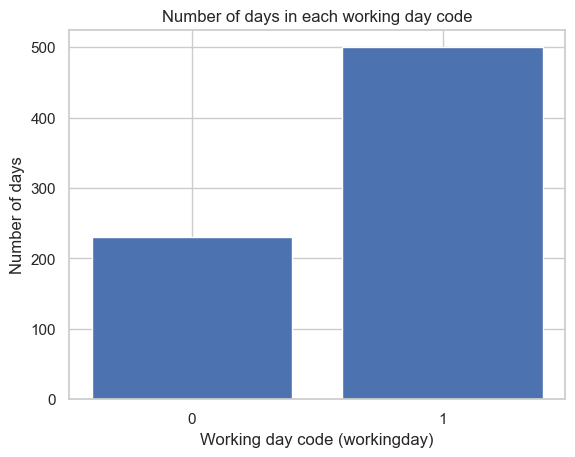

In [18]:
counts = df["workingday"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Working day code (workingday)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each working day code")
plt.show()